# Week 2: Data Preparation and Baseline
**Project:** Predicting monthly delay rates of French high-speed (TGV) routes
**Group:** Group_XX
**Team:** Oryssa Stella TALATALA, Pierre-Olivier WAFO Bakam, Hugo HOUPPE, Yehor Nalyvaiko

**Dataset:** *Régularité mensuelle TGV par liaisons* (SNCF Voyageurs), ODbL licence.
Source page: https://www.data.gouv.fr/datasets/regularite-mensuelle-tgv-par-liaisons
The notebook downloads the CSV itself from the official data.gouv.fr link (section 1) and stores it in `data/raw/`. If your network blocks the download, save the file manually under the same name (see `data/raw/README.md`).

**What this notebook does (Lab 5, Week 2 objectives)**
1. Load, clean and validate the raw data (with a row-by-row cleaning log).
2. Analyse missing values, features and the target distribution.
3. Build leakage-safe features and audit every column.
4. Define a temporal train / validation / test split.
5. Implement baselines and evaluate them with appropriate metrics.

**Problem statement.** For a given TGV route (departure station, arrival station) and a given month, predict the share of trains that arrive late, using only information available *before* that month starts (history of the route, scheduled traffic, calendar).

## 0. Setup

In [ ]:
import re, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             f1_score, roc_auc_score, average_precision_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)

DATA_URL = "https://www.data.gouv.fr/api/1/datasets/r/91fe399d-cafa-4e72-8ba3-56d8717fdad4"  # CSV resource of the dataset page
RAW_PATH = Path("../data/raw/regularite-mensuelle-tgv-aqst.csv")
PROC_DIR = Path("../data/processed")
FIG_DIR = Path("../report/figures")
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

VAL_MONTHS = 12    # most recent months kept for validation
TEST_MONTHS = 12   # very last months kept for the final test

# Plot style: one accent colour for our model, grey for reference points
BLUE, ORANGE, GREY, INK = "#257de0", "#f47230", "#9c9c9c", "#191919"
def style(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)

## 1. Download and load the raw data

In [2]:
import datetime, urllib.request

def download_raw(url, dest):
    dest.parent.mkdir(parents=True, exist_ok=True)
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ESILV ML course project)"})
    try:
        with urllib.request.urlopen(req, timeout=120) as r:
            content = r.read()
        if len(content) < 1000 or content.lstrip()[:1] == b"<":
            raise ValueError("response is not a CSV file (got a web page or an empty answer)")
        dest.write_bytes(content)
    except Exception as e:
        raise RuntimeError(
            f"Automatic download failed ({e}). Open https://www.data.gouv.fr/datasets/regularite-mensuelle-tgv-par-liaisons "
            f"in a browser, download the CSV and save it as {dest.resolve()}") from e
    (dest.parent / "download_info.txt").write_text(
        f"source: {url}\ndownloaded: {datetime.datetime.now().isoformat(timespec='seconds')}\nbytes: {len(content)}\n")

if RAW_PATH.exists():
    print("Raw file already present, download skipped:", RAW_PATH)
else:
    download_raw(DATA_URL, RAW_PATH)
    print("Downloaded", RAW_PATH, f"({RAW_PATH.stat().st_size/1e6:.1f} MB)")

def read_any(path):
    for enc in ("utf-8-sig", "latin-1"):
        for sep in (";", ",", "\t"):
            try:
                d = pd.read_csv(path, sep=sep, encoding=enc, low_memory=False)
            except UnicodeDecodeError:
                break
            if d.shape[1] > 5:
                return d
    raise ValueError("Could not parse the CSV: check separator and encoding.")

raw = read_any(RAW_PATH)
print("Raw shape:", raw.shape)
print("Columns:")
for c in raw.columns:
    print("  -", c)
raw.head(3)

Downloaded ..\data\raw\regularite-mensuelle-tgv-aqst.csv (2.9 MB)
Raw shape: (12907, 26)
Columns:
  - Date
  - Service
  - Gare de départ
  - Gare d'arrivée
  - Durée moyenne du trajet
  - Nombre de circulations prévues
  - Nombre de trains annulés
  - Commentaire annulations
  - Nombre de trains en retard au départ
  - Retard moyen des trains en retard au départ
  - Retard moyen de tous les trains au départ
  - Commentaire retards au départ
  - Nombre de trains en retard à l'arrivée
  - Retard moyen des trains en retard à l'arrivée
  - Retard moyen de tous les trains à l'arrivée
  - Commentaire retards à l'arrivée
  - Nombre trains en retard > 15min
  - Retard moyen trains en retard > 15 (si liaison concurrencée par vol)
  - Nombre trains en retard > 30min
  - Nombre trains en retard > 60min
  - Prct retard pour causes externes
  - Prct retard pour cause infrastructure
  - Prct retard pour cause gestion trafic
  - Prct retard pour cause matériel roulant
  - Prct retard pour cause gest

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111


### 1.1 Map raw columns to short names
Column names contain accents and apostrophes, so we match them on normalised keywords instead of hard-coding the exact strings. If the publisher renames a column, the function stops with a clear error instead of silently picking the wrong one.

In [3]:
def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9>]+", " ", s).strip()

def find_col(df, must, mustnot=()):
    hits = [c for c in df.columns
            if all(k in norm(c) for k in must) and not any(k in norm(c) for k in mustnot)]
    if len(hits) != 1:
        raise KeyError(f"Expected exactly 1 column for {must} (excluding {list(mustnot)}), "
                       f"got {hits}. Available columns: {list(df.columns)}")
    return hits[0]

COLMAP = {
    "date":      find_col(raw, ["date"]),
    "service":   find_col(raw, ["service"]),
    "dep":       find_col(raw, ["gare", "depart"]),
    "arr":       find_col(raw, ["gare", "arrivee"]),
    "duration":  find_col(raw, ["duree"]),
    "planned":   find_col(raw, ["circulations", "prevues"]),
    "cancelled": find_col(raw, ["annules"], mustnot=["commentaire"]),
    "late_arr":  find_col(raw, ["nombre", "retard", "arrivee"],
                          mustnot=["commentaire", "moyen", ">", "15", "30", "60"]),
}
pd.Series(COLMAP, name="raw column").to_frame()

,raw column
date,Date
service,Service
dep,Gare de départ
arr,Gare d'arrivée
duration,Durée moyenne du trajet
planned,Nombre de circulations prévues
cancelled,Nombre de trains annulés
late_arr,Nombre de trains en retard à l'arrivée


## 2. Cleaning

**Cleaning rules and why**
- **Station placeholder `0`.** The publisher's own forum has a user report that some departure/arrival stations are filled with `0` instead of a name. We cannot recover the true station. Keeping such rows as a pseudo-route "X > UNKNOWN" would silently mix several real routes into one series and corrupt the lag features, so we drop them from the modelling table and report how many rows are affected.
- **Dates** are `YYYY-MM`; we convert them to the first day of the month.
- **Invalid counts** (negative, missing, more late trains than trains that ran) are removed and counted in the log.
- **Duplicates** on (date, service, departure, arrival) are aggregated, not silently dropped.
- **Target definition (our own, to be checked by the group).** `late_rate = late arrivals / trains that actually ran`, where trains that ran = scheduled minus cancelled. We use trains that ran as denominator so that cancellations do not mechanically lower the delay rate.

In [4]:
df = raw[list(COLMAP.values())].rename(columns={v: k for k, v in COLMAP.items()}).copy()
log = [("raw rows", len(df))]

# --- dates
d = pd.to_datetime(df["date"].astype(str).str.strip(), format="%Y-%m", errors="coerce")
if d.isna().mean() > 0.5:
    d = pd.to_datetime(df["date"], errors="coerce")
df["date"] = d.dt.to_period("M").dt.to_timestamp()

# --- text columns
for c in ["service", "dep", "arr"]:
    df[c] = df[c].astype("string").str.strip().str.upper()
n_zero = {c: int(df[c].isin(["0", ""]).sum()) for c in ["dep", "arr"]}
for c in ["dep", "arr"]:
    df[c] = df[c].replace({"0": "UNKNOWN", "": "UNKNOWN"}).fillna("UNKNOWN").astype(str)
df["service"] = df["service"].fillna("UNKNOWN").astype(str)
print("Rows with placeholder station '0' or empty (before dropping):", n_zero)

# --- numeric columns
for c in ["duration", "planned", "cancelled", "late_arr"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

def drop_rows(mask, why):
    global df
    log.append((f"dropped: {why}", int(mask.sum())))
    df = df.loc[~mask].copy()

drop_rows(df["date"].isna(), "unparseable date")
drop_rows((df["dep"] == "UNKNOWN") | (df["arr"] == "UNKNOWN"), "station missing or '0' (route cannot be identified)")
drop_rows(df[["planned", "cancelled", "late_arr"]].isna().any(axis=1), "missing planned/cancelled/late counts")
drop_rows(df["planned"] <= 0, "no scheduled trains")
df["running"] = df["planned"] - df["cancelled"]
drop_rows(df["running"] <= 0, "no train actually ran")
drop_rows((df["late_arr"] < 0) | (df["late_arr"] > df["running"]), "late count outside [0, trains that ran]")
drop_rows(df.duplicated(), "exact duplicate rows")

# --- duplicated keys with different values: aggregate
KEY = ["date", "service", "dep", "arr"]
n_dupkey = int(df.duplicated(KEY, keep=False).sum())
if n_dupkey:
    df = (df.groupby(KEY, as_index=False)
            .agg(duration=("duration", "mean"), planned=("planned", "sum"),
                 cancelled=("cancelled", "sum"), late_arr=("late_arr", "sum"),
                 running=("running", "sum")))
log.append(("rows involved in duplicated keys (aggregated)", n_dupkey))

# --- target and route identifier
df["late_rate"] = df["late_arr"] / df["running"]
df["liaison"] = df["service"] + " | " + df["dep"] + " > " + df["arr"]
df = df.sort_values(["liaison", "date"]).reset_index(drop=True)
log.append(("clean rows kept", len(df)))
pd.DataFrame(log, columns=["step", "rows"])

Rows with placeholder station '0' or empty (before dropping): {'dep': 0, 'arr': 0}


,step,rows
0,raw rows,12907
1,dropped: unparseable date,0
2,dropped: station missing or '0' (route cannot ...,0
3,dropped: missing planned/cancelled/late counts,0
4,dropped: no scheduled trains,73
5,dropped: no train actually ran,0
6,"dropped: late count outside [0, trains that ran]",0
7,dropped: exact duplicate rows,0
8,rows involved in duplicated keys (aggregated),0
9,clean rows kept,12834


## 3. Exploratory analysis: missing values, features, target

In [5]:
print("Period:", df["date"].min().date(), "to", df["date"].max().date())
print("Routes (liaisons):", df["liaison"].nunique(), "| services:", df["service"].value_counts().to_dict())

miss = df.isna().mean().mul(100).round(2).rename("% missing").to_frame()
print("\nMissing values after cleaning (%):")
if (miss["% missing"] > 0).any():
    display(miss[miss["% missing"] > 0])
else:
    print("No missing values left in the kept columns.")

months_per_route = df.groupby("liaison")["date"].nunique()
print("\nMonths of history per route:")
display(months_per_route.describe().round(1).to_frame("months"))

df[["duration", "planned", "cancelled", "late_arr", "running", "late_rate"]].describe().round(3)

Period: 2018-01-01 to 2026-09-01
Routes (liaisons): 146 | services: {'NATIONAL': 11293, 'INTERNATIONAL': 1541}

Missing values after cleaning (%):
No missing values left in the kept columns.

Months of history per route:


,months
count,146.0
mean,87.9
std,36.2
min,3.0
25%,104.0
50%,104.0
75%,105.0
max,105.0


,duration,planned,cancelled,late_arr,running,late_rate
count,12834.000,12834.000,12834.000,12834.000,12834.000,12834.000
mean,171.664,274.999,8.283,39.096,266.716,0.149
std,87.023,183.479,21.863,32.414,180.713,0.084
min,35.000,1.000,0.000,0.000,1.000,0.000
25%,100.000,153.000,0.000,16.000,146.000,0.094
50%,164.000,232.000,2.000,31.000,225.000,0.134
75%,224.000,367.000,6.750,53.000,351.000,0.187
max,786.000,1104.000,297.000,376.000,1099.000,1.000


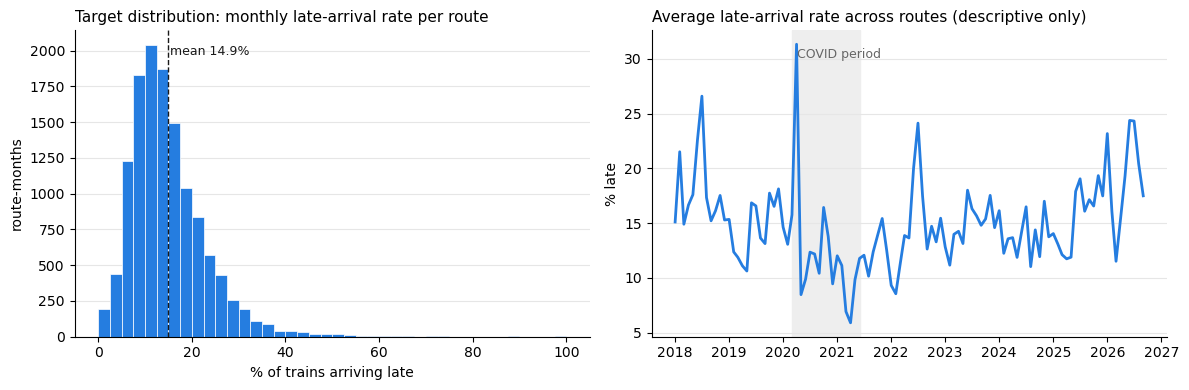

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.hist(df["late_rate"] * 100, bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(df["late_rate"].mean() * 100, color=INK, linewidth=1, linestyle="--")
ax.text(df["late_rate"].mean() * 100 + 0.5, ax.get_ylim()[1] * 0.92,
        f"mean {df['late_rate'].mean()*100:.1f}%", color=INK, fontsize=9)
ax.set_title("Target distribution: monthly late-arrival rate per route", loc="left", fontsize=11)
ax.set_xlabel("% of trains arriving late"); ax.set_ylabel("route-months")
style(ax)

ax = axes[1]
monthly = df.groupby("date")["late_rate"].mean() * 100
ax.plot(monthly.index, monthly.values, color=BLUE, linewidth=2)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"), color="#eeeeee", zorder=0)
ax.text(pd.Timestamp("2020-04-01"), ax.get_ylim()[1] * 0.95, "COVID period", fontsize=9, color="#666666", va="top")
ax.set_title("Average late-arrival rate across routes (descriptive only)", loc="left", fontsize=11)
ax.set_ylabel("% late"); style(ax)

plt.tight_layout()
plt.savefig(FIG_DIR / "eda_target.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading guide for the group (fill in after running):**
- Is the target skewed? Are there outlier months with a very high late rate?
- Is there visible seasonality (summer, winter)? Is there a trend?
- How strongly does the COVID period (2020-2021) differ? We keep it in the data for now and will test excluding it in Week 3.
- Caveat from the publisher: one TGV can count in several routes, so route-level rows are not independent and must not be summed to a national figure. We only use this table at route level.

## 4. Feature engineering and leakage audit

We frame the task as **one-step-ahead forecasting**: when predicting month *t* for a route, everything up to month *t-1* is known. Features are therefore built only from past months, the timetable and the calendar. Everything measured during month *t* itself (delays at departure, mean delays, delay-cause percentages, cancellations) is an outcome of that month and is excluded.

In [7]:
def add_lag(frame, col, k, name):
    right = frame[["liaison", "date", col]].copy()
    right["date"] = right["date"] + pd.DateOffset(months=k)   # value from k months ago lands on month t
    right = right.rename(columns={col: name})
    return frame.merge(right, on=["liaison", "date"], how="left")

feat = df.copy()
for k in (1, 2, 3, 12):
    feat = add_lag(feat, "late_rate", k, f"lag{k}")
feat["lag_mean3"] = feat[["lag1", "lag2", "lag3"]].mean(axis=1)
feat["month"] = feat["date"].dt.month
feat["month_sin"] = np.sin(2 * np.pi * feat["month"] / 12)
feat["month_cos"] = np.cos(2 * np.pi * feat["month"] / 12)
feat = feat.sort_values(["liaison", "date"]).reset_index(drop=True)
assert len(feat) == len(df), "lag merge changed the number of rows"

NUM_COLS = ["lag1", "lag2", "lag3", "lag12", "lag_mean3", "planned", "duration", "month_sin", "month_cos"]
CAT_COLS = ["service", "dep", "arr"]
TARGET = "late_rate"

audit = pd.DataFrame([
    ("lag1, lag2, lag3, lag12, lag_mean3", "past late rate of the same route", "KEPT", "built from strictly earlier months"),
    ("planned", "scheduled trains in the month", "KEPT", "timetable is known in advance"),
    ("duration", "average trip duration", "KEPT", "structural property of the route"),
    ("month_sin, month_cos", "seasonality", "KEPT", "calendar"),
    ("service, dep, arr", "route identity", "KEPT (categorical)", "structural"),
    ("cancelled, running, late_arr", "same-month outcomes", "DROPPED", "known only after the month ends; late_arr defines the target"),
    ("all other raw columns", "delays at departure, mean delays, delay-cause shares, >15/30/60 min counts, comments",
     "DROPPED", "measured over the very month we predict"),
], columns=["feature(s)", "meaning", "decision", "reason"])
audit

,feature(s),meaning,decision,reason
0,"lag1, lag2, lag3, lag12, lag_mean3",past late rate of the same route,KEPT,built from strictly earlier months
1,planned,scheduled trains in the month,KEPT,timetable is known in advance
2,duration,average trip duration,KEPT,structural property of the route
3,"month_sin, month_cos",seasonality,KEPT,calendar
4,"service, dep, arr",route identity,KEPT (categorical),structural
5,"cancelled, running, late_arr",same-month outcomes,DROPPED,known only after the month ends; late_arr defi...
6,all other raw columns,"delays at departure, mean delays, delay-cause ...",DROPPED,measured over the very month we predict


In [8]:
print("Share of rows with a missing lag (cold start or gap in the series):")
display((feat[["lag1", "lag2", "lag3", "lag12", "lag_mean3"]].isna().mean() * 100).round(1).to_frame("% missing"))

Share of rows with a missing lag (cold start or gap in the series):


,% missing
lag1,1.7
lag2,2.9
lag3,4.0
lag12,13.4
lag_mean3,1.2


## 5. Train / validation / test split (temporal)

A random split would let the model see later months while predicting earlier ones, which overstates performance. We split **by time**: the last 12 months are the test set, the 12 months before are validation (used to tune the regularisation of the linear baseline), everything earlier is training. Imputers, scalers and encoders are fitted on the training set only, inside a scikit-learn `Pipeline`.

In [9]:
months = np.sort(feat["date"].unique())
assert len(months) > VAL_MONTHS + TEST_MONTHS + 12, "not enough months for this split"
test_start = months[-TEST_MONTHS]
val_start = months[-(TEST_MONTHS + VAL_MONTHS)]
feat["split"] = np.where(feat["date"] >= test_start, "test",
                 np.where(feat["date"] >= val_start, "val", "train"))

train = feat[feat["split"] == "train"].copy()
val = feat[feat["split"] == "val"].copy()
test = feat[feat["split"] == "test"].copy()
assert train["date"].max() < val["date"].min() <= val["date"].max() < test["date"].min()

summary = (feat.groupby("split")
           .agg(rows=("date", "size"), first_month=("date", "min"), last_month=("date", "max"),
                routes=("liaison", "nunique"), mean_late_rate=(TARGET, "mean"))
           .loc[["train", "val", "test"]])
summary["first_month"] = summary["first_month"].dt.strftime("%Y-%m")
summary["last_month"] = summary["last_month"].dt.strftime("%Y-%m")
display(summary.round(4))

unseen = set(test["liaison"]) - set(train["liaison"])
print(f"Test routes never seen in training: {len(unseen)} "
      f"({test['liaison'].isin(unseen).mean()*100:.1f}% of test rows)")

,rows,first_month,last_month,routes,mean_late_rate
split,,,,,
train,9888,2018-01,2024-09,130,0.1439
val,1494,2024-10,2025-09,135,0.1473
test,1452,2025-10,2026-09,121,0.1880


Test routes never seen in training: 2 (1.7% of test rows)


## 6. Baselines (regression)

**Task:** regression of `late_rate` (a share between 0 and 1; an error of 0.01 is one percentage point).

| ID | Baseline | Why it is useful |
|----|----------|------------------|
| B0 | Global training mean | Floor: any model must beat a constant |
| B1 | Mean late rate per route (training) | Simple statistical model; captures that some routes are chronically late |
| B2 | Persistence: last month's late rate | Strong naive forecast for time series |
| B3 | Seasonal naive: same month last year | Tests whether seasonality is stable |
| **B4** | **Ridge linear regression** (lags, calendar, scheduled traffic, route one-hot) | **Our reference baseline** that Week 3 models must beat |

Where a lag is missing, B2 and B3 fall back to the route mean (B1), then to the global mean. **Metrics:** MAE (main, easy to read in percentage points), RMSE (penalises large misses), R². Model selection (Ridge alpha) uses validation MAE only; the test set is looked at once, at the end.

In [10]:
global_mean = train[TARGET].mean()
route_mean = train.groupby("liaison")[TARGET].mean()

def pred_b0(d): return np.full(len(d), global_mean)
def pred_b1(d): return d["liaison"].map(route_mean).fillna(global_mean).to_numpy()
def pred_b2(d): return d["lag1"].fillna(pd.Series(pred_b1(d), index=d.index)).to_numpy()
def pred_b3(d): return d["lag12"].fillna(pd.Series(pred_b1(d), index=d.index)).to_numpy()

def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
    ])

FEATURES = NUM_COLS + CAT_COLS
alpha_rows, best = [], None
for alpha in [0.1, 1, 10, 100, 1000]:
    m = Pipeline([("pre", make_pre()), ("model", Ridge(alpha=alpha))]).fit(train[FEATURES], train[TARGET])
    mae_val = mean_absolute_error(val[TARGET], np.clip(m.predict(val[FEATURES]), 0, 1))
    alpha_rows.append({"alpha": alpha, "val MAE": mae_val})
    if best is None or mae_val < best[0]:
        best = (mae_val, alpha, m)
ridge, BEST_ALPHA = best[2], best[1]
print("Ridge alpha selected on validation:", BEST_ALPHA)
pd.DataFrame(alpha_rows).round(5)

Ridge alpha selected on validation: 10


,alpha,val MAE
0,0.1,0.03898
1,1.0,0.03892
2,10.0,0.03880
3,100.0,0.03924
4,1000.0,0.03973


In [11]:
def pred_b4(d): return np.clip(ridge.predict(d[FEATURES]), 0, 1)

def metrics(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))), "R2": r2_score(y, p)}

models = {
    "B0 Global mean": pred_b0,
    "B1 Route mean": pred_b1,
    "B2 Persistence (lag1)": pred_b2,
    "B3 Seasonal naive (lag12)": pred_b3,
    "B4 Ridge regression": pred_b4,
}
rows = []
for name, fn in models.items():
    for split_name, d in (("val", val), ("test", test)):
        rows.append({"model": name, "split": split_name, **metrics(d[TARGET], fn(d))})
res = pd.DataFrame(rows)
res_wide = res.pivot(index="model", columns="split", values=["MAE", "RMSE", "R2"]).round(4)
res_wide = res_wide[[("MAE", "val"), ("MAE", "test"), ("RMSE", "val"), ("RMSE", "test"), ("R2", "val"), ("R2", "test")]]
res_wide

MAE            RMSE              R2        
split                         val    test     val    test     val    test
model                                                                    
B0 Global mean             0.0541  0.0694  0.0785  0.0980 -0.0019 -0.2546
B1 Route mean              0.0430  0.0609  0.0675  0.0866  0.2594  0.0218
B2 Persistence (lag1)      0.0467  0.0566  0.0639  0.0751  0.3351  0.2640
B3 Seasonal naive (lag12)  0.0508  0.0633  0.0784  0.0874 -0.0010  0.0018
B4 Ridge regression        0.0388  0.0524  0.0569  0.0704  0.4738  0.3534

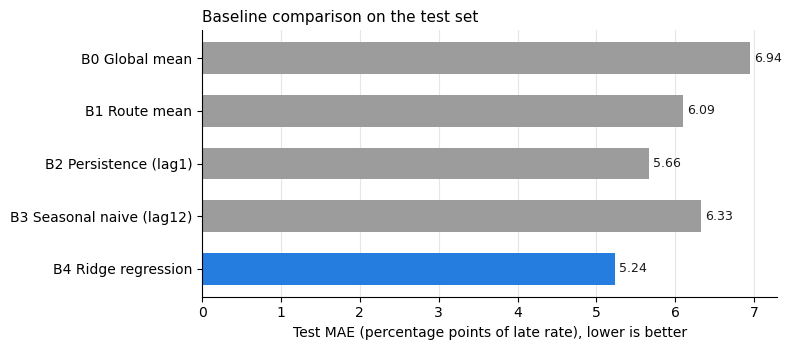

In [12]:
t = res[res["split"] == "test"].set_index("model")["MAE"] * 100
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [BLUE if m.startswith("B4") else GREY for m in t.index]
bars = ax.barh(t.index[::-1], t.values[::-1], color=colors[::-1], height=0.6)
for b, v in zip(bars, t.values[::-1]):
    ax.text(v + 0.05, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center", fontsize=9, color=INK)
ax.set_xlabel("Test MAE (percentage points of late rate), lower is better")
ax.set_title("Baseline comparison on the test set", loc="left", fontsize=11)
style(ax); ax.grid(axis="x", color="#e6e6e6", linewidth=0.8); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "baseline_mae_test.png", dpi=150, bbox_inches="tight"); plt.show()

### 6.1 First error analysis (Ridge, test set)

In [13]:
test = test.assign(pred_b4=pred_b4(test), abs_err=lambda d: (d[TARGET] - d["pred_b4"]).abs())
by_route = (test.groupby("liaison")
            .agg(months=("abs_err", "size"), MAE=("abs_err", "mean"), mean_late=(TARGET, "mean"))
            .query("months >= 6").sort_values("MAE", ascending=False))
print("Routes with the largest test error (at least 6 test months):")
display(by_route.head(10).round(4))
print("MAE by service:")
display(test.groupby("service")["abs_err"].agg(["size", "mean"]).round(4))

Routes with the largest test error (at least 6 test months):


,months,MAE,mean_late
liaison,,,
INTERNATIONAL | PARIS EST > STUTTGART,12,0.2209,0.5744
NATIONAL | BORDEAUX ST JEAN > TOURCOING,12,0.1261,0.2151
NATIONAL | MARSEILLE ST CHARLES > TOURCOING,12,0.1097,0.2170
INTERNATIONAL | PARIS EST > FRANCFORT,12,0.0907,0.3342
NATIONAL | MACON LOCHE > PARIS LYON,12,0.0802,0.3377
NATIONAL | LILLE > MARSEILLE ST CHARLES,12,0.0801,0.2503
NATIONAL | MARNE LA VALLEE > MARSEILLE ST CHARLES,12,0.0766,0.2560
INTERNATIONAL | PARIS LYON > ITALIE,12,0.0763,0.2489
NATIONAL | PARIS LYON > CHAMBERY CHALLES LES EAUX,12,0.0750,0.2525


MAE by service:


,size,mean
service,,
INTERNATIONAL,144,0.0660
NATIONAL,1308,0.0509


## 7. Secondary view: classification baseline

To keep the option open for a classification framing, we define a "high-delay month" as a route-month whose late rate exceeds the **75th percentile of the training set** (threshold computed on training data only). Baselines: majority class, persistence (last month high), and logistic regression with balanced class weights. Metrics: F1 on the positive class, ROC-AUC and PR-AUC, because the positive class is a minority.

In [14]:
thr = train[TARGET].quantile(0.75)
for d in (train, val, test):
    d["high"] = (d[TARGET] > thr).astype(int)
print(f"Threshold (train 75th percentile): {thr:.3f} | positive rate train/val/test: "
      f"{train['high'].mean():.2f} / {val['high'].mean():.2f} / {test['high'].mean():.2f}")

clf = Pipeline([("pre", make_pre()),
                ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))]
               ).fit(train[FEATURES], train["high"])

def clf_scores(d, kind):
    y = d["high"]
    if kind == "majority":
        return {"F1": f1_score(y, np.zeros(len(d), dtype=int), zero_division=0), "ROC-AUC": 0.5, "PR-AUC": y.mean()}
    if kind == "persistence":
        p = (d["lag1"].fillna(0) > thr).astype(int)
        return {"F1": f1_score(y, p, zero_division=0), "ROC-AUC": roc_auc_score(y, d["lag1"].fillna(d["lag1"].median())),
                "PR-AUC": average_precision_score(y, d["lag1"].fillna(d["lag1"].median()))}
    proba = clf.predict_proba(d[FEATURES])[:, 1]
    return {"F1": f1_score(y, (proba > 0.5).astype(int), zero_division=0),
            "ROC-AUC": roc_auc_score(y, proba), "PR-AUC": average_precision_score(y, proba)}

rows = []
for kind, name in [("majority", "C0 Majority class"), ("persistence", "C1 Persistence (lag1 > thr)"),
                   ("logreg", "C2 Logistic regression")]:
    for sp, d in (("val", val), ("test", test)):
        rows.append({"model": name, "split": sp, **clf_scores(d, kind)})
pd.DataFrame(rows).pivot(index="model", columns="split", values=["F1", "ROC-AUC", "PR-AUC"]).round(3)

Threshold (train 75th percentile): 0.180 | positive rate train/val/test: 0.25 / 0.26 / 0.46


F1        ROC-AUC        PR-AUC       
split                         test    val    test    val   test    val
model                                                                 
C0 Majority class            0.000  0.000   0.500  0.500  0.461  0.260
C1 Persistence (lag1 > thr)  0.689  0.581   0.768  0.797  0.737  0.629
C2 Logistic regression       0.705  0.667   0.810  0.870  0.795  0.720

## 8. Save the clean dataset and results

In [15]:
out_cols = ["liaison", "date", "service", "dep", "arr", "duration", "planned", "cancelled", "running",
            "late_arr", TARGET, "lag1", "lag2", "lag3", "lag12", "lag_mean3", "month", "split"]
feat[out_cols].to_csv(PROC_DIR / "tgv_liaisons_clean.csv", index=False)
res_wide.to_csv(PROC_DIR / "baseline_results_regression.csv")
pd.DataFrame(log, columns=["step", "rows"]).to_csv(PROC_DIR / "cleaning_log.csv", index=False)
print("Saved:", sorted(p.name for p in PROC_DIR.iterdir()))

Saved: ['baseline_results_regression.csv', 'cleaning_log.csv', 'tgv_liaisons_clean.csv']


## 9. Summary for the Week 2 report (to complete after running)

1. **Cleaning:** how many rows were removed and why (see cleaning log), how many rows had an unusable station (`0`).
2. **Target:** distribution, seasonality, effect of COVID.
3. **Split:** train / validation / test date ranges and sizes (table above).
4. **Baselines:** which model wins on the test set, by how much, and whether Ridge improves on persistence. If persistence is hard to beat, say so: it tells us how much of the delay rate is simply inertia.
5. **Limitations:** target definition is ours; one train counts in several routes; monthly aggregation hides daily events; rows with unusable stations were dropped.
6. **Next (Week 3):** random forest and gradient boosting, feature selection comparison, hyperparameter tuning on validation, time-series cross-validation, SHAP or permutation importance.